In [38]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)

print("All required libraries imported successfully!")

All required libraries imported successfully!


# Locate and Verify the Dataset

## What we will perform

We will locate the malaria cell image dataset and verify that the
Parasitized and Uninfected image folders are available.

In [39]:
# Define the path to the image dataset

dataset_path = "dataset/cell_images"

# Check whether the dataset folder exists
if os.path.exists(dataset_path):
    print("Dataset folder found successfully!")
else:
    print("Dataset folder was not found.")

Dataset folder found successfully!


In [40]:
# List the folders inside the dataset

classes = os.listdir(dataset_path)

print("Classes found in the dataset:")
for class_name in classes:
    print("-", class_name)

Classes found in the dataset:
- Parasitized
- Uninfected


In [41]:
# Count images in each class

for class_name in classes:
    class_path = os.path.join(dataset_path, class_name)
    
    image_files = [
        file for file in os.listdir(class_path)
        if file.lower().endswith((".png", ".jpg", ".jpeg"))
    ]
    
    print(f"{class_name}: {len(image_files)} images")

Parasitized: 13779 images
Uninfected: 13779 images


In [42]:
dataset_path = "dataset/cell_images"

if os.path.exists(dataset_path):
    print("Dataset folder found successfully!")
else:
    print("Dataset folder was not found.")

Dataset folder found successfully!


In [43]:
classes = os.listdir(dataset_path)

print("Classes found in the dataset:")
for class_name in classes:
    print("-", class_name)

Classes found in the dataset:
- Parasitized
- Uninfected


In [44]:
for class_name in classes:
    class_path = os.path.join(dataset_path, class_name)
    
    image_files = [
        file for file in os.listdir(class_path)
        if file.lower().endswith((".png", ".jpg", ".jpeg"))
    ]
    
    print(f"{class_name}: {len(image_files)} images")

Parasitized: 13779 images
Uninfected: 13779 images


# Explore and Display Sample Images

## What we will perform

We will display sample images from the Parasitized and Uninfected
classes to understand the visual characteristics of the dataset.

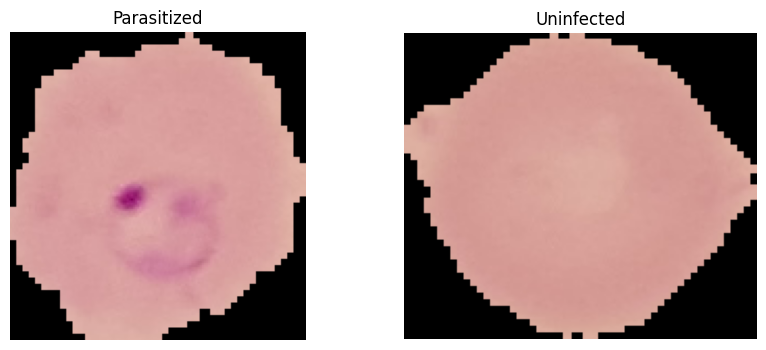

In [45]:
# Select one image from each class

parasitized_path = os.path.join(
    dataset_path,
    "Parasitized",
    os.listdir(os.path.join(dataset_path, "Parasitized"))[0]
)

uninfected_path = os.path.join(
    dataset_path,
    "Uninfected",
    os.listdir(os.path.join(dataset_path, "Uninfected"))[0]
)

# Open the images
parasitized_image = Image.open(parasitized_path)
uninfected_image = Image.open(uninfected_path)

# Display the images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(parasitized_image)
plt.title("Parasitized")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(uninfected_image)
plt.title("Uninfected")
plt.axis("off")

plt.show()

# Check Image Dimensions

## What we will perform

We will examine the dimensions of sample images before preprocessing.
This will help us understand the image format used in the dataset.

In [46]:
print("Parasitized image size:", parasitized_image.size)
print("Uninfected image size:", uninfected_image.size)

Parasitized image size: (142, 148)
Uninfected image size: (160, 139)


# Preprocess the Images

## What we will perform

We will resize all images to a standard size of 64 × 64 pixels and
convert them into numerical arrays for machine-learning processing.

In [47]:
# Define the standard image size

image_size = (32, 32)

# Resize the sample images
parasitized_resized = parasitized_image.resize(image_size)
uninfected_resized = uninfected_image.resize(image_size)

print("Original Parasitized size:", parasitized_image.size)
print("Resized Parasitized size:", parasitized_resized.size)

print("Original Uninfected size:", uninfected_image.size)
print("Resized Uninfected size:", uninfected_resized.size)

Original Parasitized size: (142, 148)
Resized Parasitized size: (32, 32)
Original Uninfected size: (160, 139)
Resized Uninfected size: (32, 32)


In [48]:
# Convert the resized images into NumPy arrays

parasitized_array = np.array(parasitized_resized)
uninfected_array = np.array(uninfected_resized)

print("Parasitized array shape:", parasitized_array.shape)
print("Uninfected array shape:", uninfected_array.shape)

Parasitized array shape: (32, 32, 3)
Uninfected array shape: (32, 32, 3)


In [49]:
# Normalize pixel values

parasitized_normalized = parasitized_array / 255.0
uninfected_normalized = uninfected_array / 255.0

print("Minimum pixel value:", parasitized_normalized.min())
print("Maximum pixel value:", parasitized_normalized.max())

Minimum pixel value: 0.0
Maximum pixel value: 0.9333333333333333


# Select and Process the Dataset

## What we will perform

We will select a balanced sample of 5,000 images from each class.
Each image will be resized to 64 × 64 pixels and converted into
numerical features for machine-learning models.

In [50]:
# Number of images to use from each class

images_per_class = 2000

print("Images selected from each class:", images_per_class)
print("Total images selected:", images_per_class * 2)

Images selected from each class: 2000
Total images selected: 4000


# Create the Image Processing Function

## What we will perform

We will create a reusable function to preprocess each image by
resizing, converting, normalizing, and flattening the image.

In [51]:
def process_image(image_path):
    # Open the image
    image = Image.open(image_path).convert("RGB")
    
    # Resize image
    image = image.resize(image_size)
    
    # Convert image to NumPy array
    image_array = np.array(image)
    
    # Normalize pixel values between 0 and 1
    image_array = image_array / 255.0
    
    # Flatten the image into one row
    image_array = image_array.flatten()
    
    return image_array

# Select Images from Both Classes

## What we will perform

We will randomly select 5,000 images from the Parasitized class and
5,000 images from the Uninfected class.

In [52]:
import random

# Set a fixed random seed so the same images are selected each time
random.seed(42)

# Get image file names
parasitized_files = [
    file for file in os.listdir(os.path.join(dataset_path, "Parasitized"))
    if file.lower().endswith((".png", ".jpg", ".jpeg"))
]

uninfected_files = [
    file for file in os.listdir(os.path.join(dataset_path, "Uninfected"))
    if file.lower().endswith((".png", ".jpg", ".jpeg"))
]

# Randomly select images
parasitized_selected = random.sample(parasitized_files, images_per_class)
uninfected_selected = random.sample(uninfected_files, images_per_class)

print("Selected Parasitized images:", len(parasitized_selected))
print("Selected Uninfected images:", len(uninfected_selected))

Selected Parasitized images: 2000
Selected Uninfected images: 2000


# Process the Selected Images

## What we will perform

We will preprocess the selected images and convert them into numerical
feature vectors suitable for machine-learning algorithms.

In [53]:
X = []
y = []

# Process Parasitized images
for i, file in enumerate(parasitized_selected):
    image_path = os.path.join(dataset_path, "Parasitized", file)
    
    try:
        features = process_image(image_path)
        X.append(features)
        y.append(1)
    except Exception as e:
        print("Error processing:", file)

# Process Uninfected images
for i, file in enumerate(uninfected_selected):
    image_path = os.path.join(dataset_path, "Uninfected", file)
    
    try:
        features = process_image(image_path)
        X.append(features)
        y.append(0)
    except Exception as e:
        print("Error processing:", file)

print("Images successfully processed:", len(X))
print("Labels created:", len(y))

Images successfully processed: 4000
Labels created: 4000


In [54]:
# Convert the processed data into NumPy arrays

X = np.array(X)
y = np.array(y)

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

Feature matrix shape: (4000, 3072)
Target vector shape: (4000,)


In [55]:
# Check the number of samples in each class

unique, counts = np.unique(y, return_counts=True)

print("Class distribution:")

for label, count in zip(unique, counts):
    if label == 1:
        print("Parasitized:", count)
    else:
        print("Uninfected:", count)

Class distribution:
Uninfected: 2000
Parasitized: 2000


In [56]:
from sklearn.model_selection import train_test_split

print("Train-test split function imported successfully!")

Train-test split function imported successfully!


# Split the Dataset into Training and Testing Data

## What we will perform

We will divide the dataset into 80% training data and 20% testing data. The training set will be used to train our machine-learning models, while the testing set will be used to evaluate their performance on unseen images.

In [57]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training images:", len(X_train))
print("Testing images:", len(X_test))

print("Training labels:", len(y_train))
print("Testing labels:", len(y_test))

Training images: 3200
Testing images: 800
Training labels: 3200
Testing labels: 800


In [58]:
# Step 28: Train the Decision Tree model

decision_tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)

decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [59]:
# Step 29: Predict using the Decision Tree model

y_pred_dt = decision_tree_model.predict(X_test)

print("Predictions completed successfully!")
print("Total predictions:", len(y_pred_dt))
print("First 10 predictions:", y_pred_dt[:10])

Predictions completed successfully!
Total predictions: 800
First 10 predictions: [1 0 1 1 1 0 0 0 0 1]


In [60]:
# Step 30: Evaluate Decision Tree accuracy

accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Model Evaluation")
print("--------------------------------")
print("Accuracy:", round(accuracy_dt * 100, 2), "%")

Decision Tree Model Evaluation
--------------------------------
Accuracy: 65.88 %


In [61]:
# Step 31: Classification report for Decision Tree

print("Decision Tree Classification Report")
print("------------------------------------")

print(
    classification_report(
        y_test,
        y_pred_dt,
        target_names=["Uninfected", "Parasitized"],
        zero_division=0
    )
)

Decision Tree Classification Report
------------------------------------
              precision    recall  f1-score   support

  Uninfected       0.64      0.74      0.68       400
 Parasitized       0.69      0.58      0.63       400

    accuracy                           0.66       800
   macro avg       0.66      0.66      0.66       800
weighted avg       0.66      0.66      0.66       800



Decision Tree Confusion Matrix:
[[295 105]
 [168 232]]


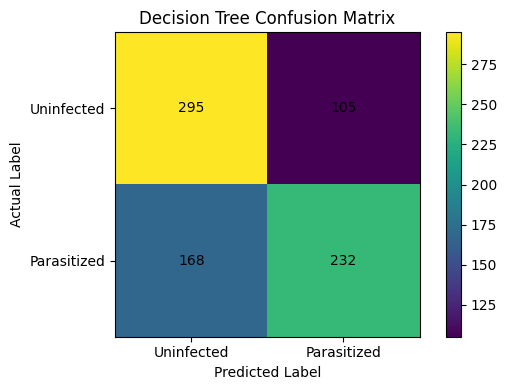

In [62]:
# Step 32: Confusion matrix for Decision Tree

cm_dt = confusion_matrix(y_test, y_pred_dt)

print("Decision Tree Confusion Matrix:")
print(cm_dt)

plt.figure(figsize=(6, 4))

plt.imshow(cm_dt, interpolation="nearest")
plt.title("Decision Tree Confusion Matrix")
plt.colorbar()

plt.xticks([0, 1], ["Uninfected", "Parasitized"])
plt.yticks([0, 1], ["Uninfected", "Parasitized"])

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm_dt[i, j],
                 ha="center", va="center")

plt.tight_layout()
plt.show()

In [63]:
# Step 33: Train the Random Forest model

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=10,
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [64]:
# Step 34: Predict using the Random Forest model

y_pred_rf = random_forest_model.predict(X_test)

print("Random Forest predictions completed successfully!")
print("Total predictions:", len(y_pred_rf))
print("First 10 predictions:", y_pred_rf[:10])

Random Forest predictions completed successfully!
Total predictions: 800
First 10 predictions: [1 1 0 1 1 0 0 0 0 1]


In [65]:
# Step 35: Evaluate Random Forest accuracy

accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Model Evaluation")
print("--------------------------------")
print("Random Forest Accuracy:", round(accuracy_rf * 100, 2), "%")
print("Decision Tree Accuracy:", round(accuracy_dt * 100, 2), "%")

if accuracy_rf > accuracy_dt:
    print("Result: Random Forest performed better.")
elif accuracy_rf < accuracy_dt:
    print("Result: Decision Tree performed better.")
else:
    print("Result: Both models achieved the same accuracy.")

Random Forest Model Evaluation
--------------------------------
Random Forest Accuracy: 73.38 %
Decision Tree Accuracy: 65.88 %
Result: Random Forest performed better.


In [66]:
# Step 36: Classification report for Random Forest

print("Random Forest Classification Report")
print("------------------------------------")

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["Uninfected", "Parasitized"],
        zero_division=0
    )
)

Random Forest Classification Report
------------------------------------
              precision    recall  f1-score   support

  Uninfected       0.71      0.78      0.75       400
 Parasitized       0.76      0.69      0.72       400

    accuracy                           0.73       800
   macro avg       0.74      0.73      0.73       800
weighted avg       0.74      0.73      0.73       800



Random Forest Confusion Matrix:
[[312  88]
 [125 275]]


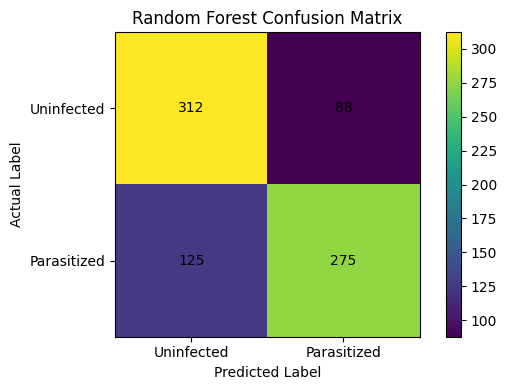

In [67]:
# Step 37: Confusion matrix for Random Forest

cm_rf = confusion_matrix(y_test, y_pred_rf)

print("Random Forest Confusion Matrix:")
print(cm_rf)

plt.figure(figsize=(6, 4))

plt.imshow(cm_rf, interpolation="nearest")
plt.title("Random Forest Confusion Matrix")
plt.colorbar()

plt.xticks([0, 1], ["Uninfected", "Parasitized"])
plt.yticks([0, 1], ["Uninfected", "Parasitized"])

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm_rf[i, j],
                 ha="center", va="center")

plt.tight_layout()
plt.show()

Model Accuracy Comparison
-------------------------
Decision Tree: 65.88%
Random Forest: 73.38%


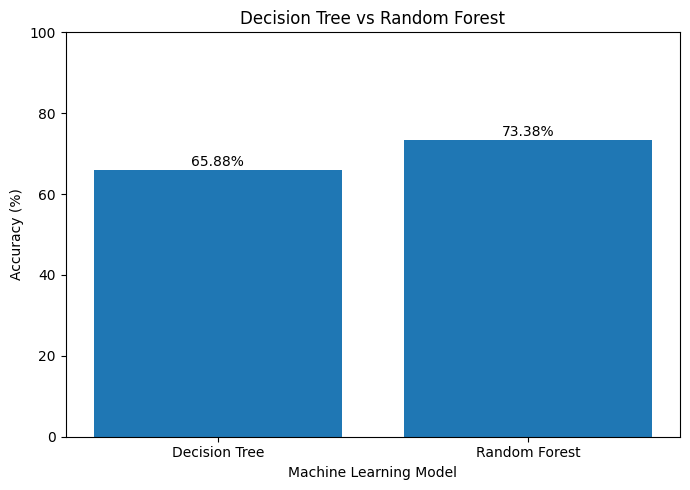

In [68]:
# Step 38: Compare model accuracy

models = ["Decision Tree", "Random Forest"]
accuracies = [accuracy_dt * 100, accuracy_rf * 100]

print("Model Accuracy Comparison")
print("-------------------------")
print(f"Decision Tree: {accuracies[0]:.2f}%")
print(f"Random Forest: {accuracies[1]:.2f}%")

plt.figure(figsize=(7, 5))

bars = plt.bar(models, accuracies)

plt.title("Decision Tree vs Random Forest")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

ROC-AUC Comparison
------------------
Decision Tree AUC: 0.652
Random Forest AUC: 0.808


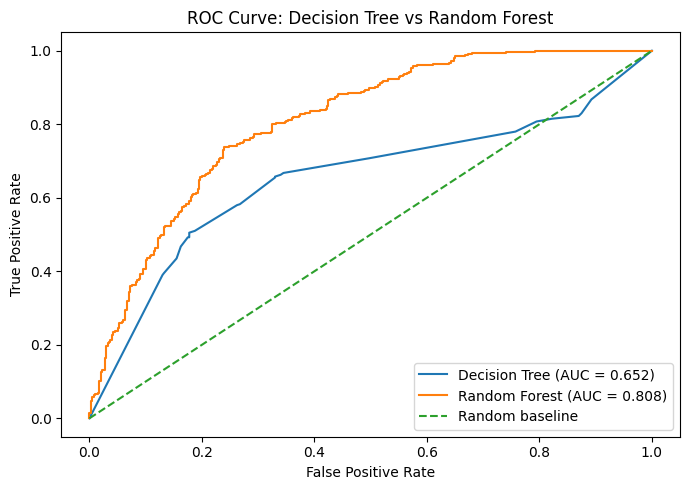

In [69]:
# Step 39: ROC curve and AUC comparison

# Get probability scores for the Parasitized class
y_prob_dt = decision_tree_model.predict_proba(X_test)[:, 1]
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

# Calculate ROC curves
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

# Calculate AUC scores
auc_dt = auc(fpr_dt, tpr_dt)
auc_rf = auc(fpr_rf, tpr_rf)

print("ROC-AUC Comparison")
print("------------------")
print(f"Decision Tree AUC: {auc_dt:.3f}")
print(f"Random Forest AUC: {auc_rf:.3f}")

# Plot ROC curves
plt.figure(figsize=(7, 5))

plt.plot(fpr_dt, tpr_dt, label=f"Decision Tree (AUC = {auc_dt:.3f})")
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc_rf:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")

plt.title("ROC Curve: Decision Tree vs Random Forest")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

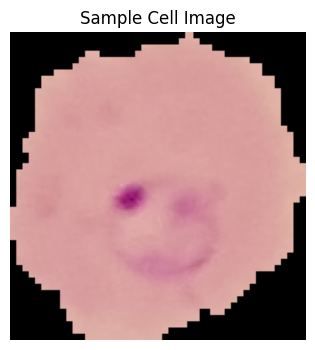

Predicted class: Parasitized


In [70]:
# Step 40: Predict the class of a sample cell image

sample_image_path = os.path.join(
    dataset_path,
    "Parasitized",
    parasitized_files[0]
)

# Process the image using the same preprocessing function
sample_features = process_image(sample_image_path)

# Convert the image into the format expected by the model
sample_features = sample_features.reshape(1, -1)

# Predict the class
sample_prediction = random_forest_model.predict(sample_features)[0]

# Display the image
plt.figure(figsize=(4, 4))
plt.imshow(Image.open(sample_image_path))
plt.title("Sample Cell Image")
plt.axis("off")
plt.show()

# Display the prediction
if sample_prediction == 1:
    print("Predicted class: Parasitized")
else:
    print("Predicted class: Uninfected")

In [71]:
# Step 41: Final model comparison

comparison_df = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Accuracy (%)": [
        round(accuracy_dt * 100, 2),
        round(accuracy_rf * 100, 2)
    ],
    "ROC-AUC": [
        round(auc_dt, 3),
        round(auc_rf, 3)
    ]
})

print("Final Model Comparison")
display(comparison_df)

best_model = comparison_df.loc[
    comparison_df["Accuracy (%)"].idxmax(), "Model"
]

print("Best model based on accuracy:", best_model)

Final Model Comparison


,Model,Accuracy (%),ROC-AUC
0,Decision Tree,65.88,0.652
1,Random Forest,73.38,0.808


Best model based on accuracy: Random Forest


## Conclusion

In this project, we developed a machine learning model to classify malaria cell images into two categories: Parasitized and Uninfected. We preprocessed 4,000 images, extracted pixel-based features, and divided the dataset into 80% training data and 20% testing data. We trained and evaluated two machine learning algorithms: Decision Tree and Random Forest.

The Decision Tree model achieved an accuracy of 65.88% and a ROC-AUC score of 0.652. The Random Forest model achieved an accuracy of 73.38% and a ROC-AUC score of 0.808. Based on these results, Random Forest performed better than Decision Tree on the test set used in this experiment.

This project helped demonstrate image preprocessing, feature extraction, model training, classification metrics, confusion matrices, and ROC curve analysis. The current approach uses simplified pixel-based features and is intended for educational purposes only; further validation and more advanced image-processing techniques would be needed before considering any real-world medical application.